# Multi-Agent Cyber-Threat Detection and Response

A college project using CrewAI, MITRE ATT&CK retrieval and deterministic validators.
This notebook analyzes **synthetic data only**. Response commands are inert recommendations.

The offline implementation and the six fixed retrieval queries are tested locally. Live-model results and fresh-Colab verification remain pending until actually run. No S1/S3 performance is claimed from mock tests.

```text
Synthetic logs → parser → loose rules → Log Analyst → Threat Intel + RAG
                                           → Risk Assessor → Response Planner
                                                    ↓
                               saved output → ground-truth evaluation
```

Run the cells from top to bottom on a Colab CPU runtime. Add `GEMINI_API_KEY` to Colab Secrets and allow notebook access. `GROQ_API_KEY` is an optional manually selected backup. The notebook embeds the project files so an unpublished GitHub repository is not required.


## 1. Setup, dependencies, secrets and configuration

In [1]:
import asyncio, base64, importlib.metadata as metadata, io, json, os, pathlib, subprocess, sys, zipfile
# Match the configured CPU embedding thread limit before importing native libraries.
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[name] = '1'
try:
    from google.colab import userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
root = pathlib.Path('/content/cyber-threat-agents') if IN_COLAB else pathlib.Path.cwd()
if not IN_COLAB and root.name == 'notebooks':
    root = root.parent
if not (root / 'src/cyberagents').exists():
    root.mkdir(parents=True, exist_ok=True)
    archive = zipfile.ZipFile(io.BytesIO(base64.b64decode("""...""")))
    for member in archive.infolist():
        target = (root / member.filename).resolve()
        if not target.is_relative_to(root.resolve()):
            raise ValueError('Unsafe archive member')
    archive.extractall(root)
os.chdir(root)
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'])
    for key in ['GEMINI_API_KEY', 'GROQ_API_KEY']:
        try:
            value = userdata.get(key)
            if value:
                os.environ[key] = value
        except userdata.SecretNotFoundError:
            pass
        except userdata.NotebookAccessError:
            print(f'Grant notebook access to {key} in Colab Secrets.')
else:
    if pathlib.Path('.env').exists():
        from dotenv import load_dotenv
        load_dotenv(override=False)
sys.path.insert(0, str(root / 'src'))
from cyberagents.config import CONFIG, CATALOG
RUN_LIVE = bool(os.environ.get({'gemini': 'GEMINI_API_KEY', 'groq': 'GROQ_API_KEY'}[CONFIG['llm']['provider']]))
print('Python:', sys.version.split()[0])
print('Live requests enabled:', RUN_LIVE)
print('Source:', CONFIG['attack']['commit'])
print('LLM:', CONFIG['llm']['provider'], CONFIG['llm']['model'])
from packaging.requirements import Requirement
for line in pathlib.Path('requirements.txt').read_text().splitlines():
    if not line.strip() or line.startswith(('#', '--')):
        continue
    requirement = Requirement(line)
    if requirement.marker and not requirement.marker.evaluate():
        continue
    name = requirement.name
    try:
        print(name, metadata.version(name))
    except metadata.PackageNotFoundError:
        print(name, 'NOT INSTALLED — install requirements.txt before live work')


Python: 3.12.10
Live requests enabled: True
Source: 50be388e93819a5d20e71cbaaeccfda157abc846
LLM: gemini gemini-3.5-flash-lite
crewai 1.15.28
google-genai 2.31.0
groq 1.7.0
sentence-transformers 6.1.0
pydantic 2.12.5
numpy 2.1.3
pandas 3.0.0
matplotlib 3.10.8
pytest 9.1.1
faiss-cpu 1.15.1
torch 2.14.1+cpu
transformers 5.20.1
huggingface-hub 1.33.0
tokenizers 0.23.3
safetensors 0.8.0
rank-bm25 0.2.2
kubernetes 36.0.2


## 2. Pinned ATT&CK knowledge base and mitigation map

In [2]:
from cyberagents.attack_kb import build_kb, verify_catalog
kb = build_kb()
verify_catalog(kb)
print('Active techniques:', len(kb['techniques']))
print('Verified catalog IDs:', len(CATALOG))
print('Techniques with mitigation relationships:', len(kb['mitigations']))


Active techniques: 706
Verified catalog IDs: 13
Techniques with mitigation relationships: 595


## 3. CPU embeddings, FAISS and semantic retrieval checks

In [3]:
from cyberagents.pipeline import check_retrieval
if IN_COLAB or RUN_LIVE:
    retrieval = check_retrieval()
    assert retrieval['passed'] >= 5, 'Retrieval target missed; record a decision before changing the index design.'
else:
    retrieval = None
    print('Real semantic retrieval is not executed in this offline notebook session. The saved retrieval check, where supplied, records the actual measured result.')


{
  "passed": 6,
  "total": 6,
  "queries": [
    {
      "query": "many failed SSH password attempts from one IP",
      "expanded_query": "many failed SSH password attempts from one IP",
      "accepted": [
        "T1110",
        "T1110.001"
      ],
      "returned": [
        "T1110.001",
        "T1110.003",
        "T1110.004",
        "T1110",
        "T1563.001"
      ],
      "passed": true
    },
    {
      "query": "one IP trying many different usernames",
      "expanded_query": "one IP trying many different usernames",
      "accepted": [
        "T1110",
        "T1110.003"
      ],
      "returned": [
        "T1110.003",
        "T1110.004",
        "T1110.001",
        "T1583.001",
        "T1584.001"
      ],
      "passed": true
    },
    {
      "query": "connection attempts to many ports on a host",
      "expanded_query": "connection attempts to many ports on a host network port scanning",
      "accepted": [
        "T1046",
        "T1595.001"
      ],
     

## 4. Synthetic environment and seed-42 logs

In [4]:
from cyberagents.generator import generate_logs
seed_dir = pathlib.Path('outputs/seed42')
if not seed_dir.exists():
    generate_logs(42, seed_dir)
for name in ['auth.log', 'access.log', 'firewall.csv']:
    print(name, 'lines:', len((seed_dir / name).read_text().splitlines()))
print('Inventory:', json.loads((seed_dir / 'asset_inventory.json').read_text()))
# Ground-truth labels remain unread until the evaluation section.


auth.log lines: 3039
access.log lines: 8007
firewall.csv lines: 15807
Inventory: {'internal_network': '10.0.0.0/24', 'hosts': {'10.0.0.10': {'name': 'ssh-srv', 'role': 'ssh server'}, '10.0.0.20': {'name': 'web-srv', 'role': 'web server'}, '10.0.0.5': {'name': 'mon-01', 'role': 'service health checks'}, '192.0.2.10': {'name': 'backup.corp-example.net', 'role': 'nightly backup target'}}, 'users': ['asharma', 'rkumar', 'deploy', 'pmehta', 'srao', 'mshah', 'npatel', 'akhan', 'vnair', 'rjain', 'pgupta', 'kdas', 'troy', 'singh', 'iyer', 'sysadmin'], 'admin_user': 'sysadmin', 'admin_working_hours_ist': [9, 19], 'monitoring_host': '10.0.0.5', 'backup_server': '192.0.2.10'}


## 5. Parsing and UTC normalization

In [5]:
from cyberagents.parser import parse_logs
events = parse_logs(seed_dir)
print('Parsed events:', len(events))
display(events[['event_id', 'source', 'ts_utc', 'event_type', 'src_ip']].head())


Parsed events: 26852


,event_id,source,ts_utc,event_type,src_ip
0,fw:000001,fw,2026-10-16 18:30:00+00:00,conn,10.0.0.5
1,fw:000002,fw,2026-10-16 18:30:01+00:00,conn,10.0.0.5
2,fw:000003,fw,2026-10-16 18:30:02+00:00,conn,10.0.0.5
3,fw:000004,fw,2026-10-16 18:30:03+00:00,conn,10.0.0.5
4,fw:000005,fw,2026-10-16 18:30:04+00:00,conn,10.0.0.5


## 6. Deterministic candidate clusters

In [6]:
from cyberagents.prefilter import prefilter
clusters = prefilter(events)
print('Candidate clusters:', len(clusters))
print('Sample-size maximum:', max(len(c['sample_lines']) for c in clusters))
display(__import__('pandas').DataFrame([{k: c[k] for k in ['cluster_id', 'rule_ids', 'line_count', 't_start', 't_end']} for c in clusters]))


Candidate clusters: 20
Sample-size maximum: 10


,cluster_id,rule_ids,line_count,t_start,t_end
0,c001,[R-SCAN],5760,2026-10-16T18:30:00+00:00,2026-10-17T18:25:19+00:00
1,c002,[R-AUTH-FAIL],12,2026-10-16T19:37:10+00:00,2026-10-16T19:38:38+00:00
2,c003,[R-SCAN],22,2026-10-16T20:37:10+00:00,2026-10-16T20:37:31+00:00
3,c004,"[R-AUTH-FAIL, R-SUCCESS-AFTER-FAIL]",13,2026-10-16T20:47:10+00:00,2026-10-16T20:52:10+00:00
4,c005,[R-SUDO-ROOT],1,2026-10-16T20:54:10+00:00,2026-10-16T20:54:10+00:00
5,c006,[R-SUCCESS-AFTER-FAIL],4,2026-10-16T21:03:08+00:00,2026-10-16T21:14:32+00:00
6,c007,[R-EGRESS],1,2026-10-16T21:07:10+00:00,2026-10-16T21:07:10+00:00
7,c008,"[R-AUTH-FAIL, R-SPRAY]",8,2026-10-16T23:37:10+00:00,2026-10-16T23:38:34+00:00
8,c009,[R-SCAN],22,2026-10-17T02:37:10+00:00,2026-10-17T02:37:31+00:00
9,c010,[R-SUCCESS-AFTER-FAIL],2,2026-10-17T04:18:28+00:00,2026-10-17T04:47:32+00:00


## 7. Schemas, validators and the test-first benchmark harness

In [7]:
import inspect
from cyberagents import schemas, validators, evaluate
print(inspect.getsource(validators.validate_mappings))
checked = subprocess.run([sys.executable, '-m', 'pytest', '-m', 'not live', '-q'], text=True, capture_output=True)
print(checked.stdout)
if checked.returncode:
    print(checked.stderr)
    raise RuntimeError('Offline suite failed')


def validate_mappings(mappings, findings, kb, retrieval_log):
    known = {f['finding_id'] for f in findings if f.get('verdict') != 'benign'}
    errors, seen = [], set()
    for mapping in mappings:
        fid = mapping['finding_id']
        if fid not in known or fid in seen:
            errors.append(f'{fid}: unknown, benign or duplicate finding mapping')
        seen.add(fid)
        choices = mapping['techniques']
        if not choices or sum(t['is_primary'] for t in choices) != 1:
            errors.append(f'{fid}: exactly one primary technique required')
        for choice in choices:
            tid = choice['technique_id']
            record = kb['techniques'].get(tid)
            if not record or tid not in retrieval_log.get(fid, []):
                errors.append(f'{fid}: {tid} unknown or not retrieved for this finding')
            elif choice.get('name') != record.get('name') or choice.get('tactic') not in record.get('tactics', []):
                errors.append(f'{fid}:

.............................................................            [100%]
============================== warnings summary ===============================
tests/test_agents.py::test_crewai_framework_uses_cached_provider_without_a_live_api
tests/test_agents.py::test_crewai_framework_uses_cached_provider_without_a_live_api
  D:\agent\.venv\Lib\site-packages\crewai\agent\core.py:425: DeprecationWarning: function_calling_llm is deprecated and will be removed in a future release.
    if self.function_calling_llm and not isinstance(

tests/test_agents.py::test_crewai_framework_uses_cached_provider_without_a_live_api
tests/test_agents.py::test_crewai_framework_uses_cached_provider_without_a_live_api
  D:\agent\.venv\Lib\site-packages\crewai\agent\core.py:433: DeprecationWarning: deprecated
    if self.allow_code_execution:

tests/test_agents.py::test_crewai_framework_uses_cached_provider_without_a_live_api
tests/test_agents.py::test_crewai_framework_uses_cached_provider_without_a_live_ap

## 8. CrewAI tasks, prompts, logged tools and cached requests

In [8]:
from cyberagents import agents, llm
print(json.dumps(agents.PROMPTS, indent=2))
print(inspect.getsource(llm.CachedLLM.text_call))
print('Each CrewAI task is validated before the next agent receives its output. Invalid items are retried once, then stripped and marked unvalidated.')


{
  "findings": [
    "Log Analyst",
    "Judge every cluster malicious, suspicious or benign using the asset inventory. Use separate findings for distinct attack stages, even when they share a cluster. Cite only shown event IDs, at most ten per finding. Explain benign dismissals: internal password mistypes followed by success, expected admin sudo in working hours, apostrophes in legitimate searches, known monitoring scans and known nightly backup transfers. A finding may reference several related clusters."
  ],
  "mappings": [
    "Threat Intel Analyst",
    "Map each non-benign validated finding to one to three ATT&CK techniques. Choose only pre-retrieved candidates or results of search_attack for this finding. Use exact catalog names and a listed tactic, exactly one primary technique, evidence-based justification and confidence. get_technique may only inspect IDs already retrieved for the same finding."
  ],
  "incidents": [
    "Risk Assessor",
    "Correlate related findings into

## 9. Full-system seed-42 run and walkthrough

In [9]:
from cyberagents.pipeline import run_system
s3_path = pathlib.Path('outputs/S3_seed42.json')
s3 = await asyncio.to_thread(run_system, 'S3', 42, live=RUN_LIVE) if RUN_LIVE or s3_path.exists() else None
if s3 is None:
    print('S3 not run: provide a Gemini key. No mock result is substituted.')
else:
    print(json.dumps({k: s3[k] for k in ['execution', 'runtime_s', 'llm_calls', 'tokens', 'cache_hits']}, indent=2))
    print(json.dumps(s3['incidents'], indent=2))


{
  "execution": "live",
  "runtime_s": 113.71900000004098,
  "llm_calls": 4,
  "tokens": 80421,
  "cache_hits": 0
}
[
  {
    "incident_id": "inc-001",
    "finding_ids": [
      "f003",
      "f004",
      "f005",
      "f007"
    ],
    "title": "Compromise of SSH Server via Brute Force, Privilege Escalation, and Data Exfiltration",
    "severity": "critical",
    "confidence": 0.95,
    "attacker_ips": [
      "203.0.113.75"
    ],
    "affected_assets": [
      "ssh-srv",
      "10.0.0.10"
    ],
    "kill_chain": [
      {
        "order": 1,
        "ts_utc": "2026-10-16T20:37:10Z",
        "finding_id": "f003",
        "technique_id": "T1595.001",
        "description": "External port scanning activity targeting the SSH server from source IP 203.0.113.75."
      },
      {
        "order": 2,
        "ts_utc": "2026-10-16T20:47:10Z",
        "finding_id": "f004",
        "technique_id": "T1110",
        "description": "Brute-force password guessing leading to successful SSH aut

## 10. S0 rules-only and S1 single-LLM baselines

In [10]:
# Refresh the deterministic development baseline for this checkout's fingerprint.
s0 = run_system('S0', 42, force=True)
print('S0 incidents:', len(s0['incidents']))
s1_path = pathlib.Path('outputs/S1_seed42.json')
s1 = await asyncio.to_thread(run_system, 'S1', 42, live=RUN_LIVE) if RUN_LIVE or s1_path.exists() else None
print('S1:', 'saved/live output available' if s1 else 'not run; API key required')


S0 incidents: 20


S1: saved/live output available


## 11. System freeze and held-out evaluation runs

In [11]:
from cyberagents.pipeline import record_system_freeze
freeze_path = pathlib.Path('outputs/system_freeze.json')
if s3 is not None and retrieval is not None and not freeze_path.exists():
    print(json.dumps(record_system_freeze(), indent=2))
if freeze_path.exists():
    for seed in CONFIG['held_out_seeds']:
        for system in ['S0', 'S1', 'S3']:
            path = pathlib.Path(f'outputs/{system}_seed{seed}.json')
            if RUN_LIVE or path.exists():
                result = await asyncio.to_thread(run_system, system, seed, live=RUN_LIVE)
                print(system, seed, result['execution'])
else:
    print('Held-out seeds remain untouched until a real current dev run and retrieval checks permit System freeze.')


{
  "decision_id": "D33",
  "source_hash": "62ba5e641bbdaf1a518bb18f6d2e80310ce44b303cce002a49718790be4b3109",
  "dev_metrics": {
    "system": "S3",
    "seed": 42,
    "detected_scenarios": [
      "A6"
    ],
    "detection_recall": 0.16666666666666666,
    "incident_precision": 1.0,
    "false_positives": 0,
    "benign_case_false_positives": 0,
    "background_false_positives": 0,
    "mapping_accuracy": 0.8,
    "a6_stages": 5,
    "a6_correlated": true,
    "hallucination_rate": 0.0,
    "nonexistent_technique_ids": 0,
    "unretrieved_technique_ids": 0,
    "invalid_evidence_refs": 0,
    "invalid_evidence_rate": 0.0,
    "runtime_s": 113.71900000004098,
    "llm_calls": 4,
    "tokens": 80421,
    "errors": [
      {
        "kind": "miss",
        "item": "A1",
        "matched_scenario": "A1",
        "cause": "Analyst dismissal/correlation"
      },
      {
        "kind": "miss",
        "item": "A2",
        "matched_scenario": "A2",
        "cause": "Analyst dismissal/co

S0 7 deterministic


S1 7 live


S3 7 live


S0 2026 deterministic


S1 2026 live


S3 2026 live


## 12. Evaluation, measured tables and charts

{
  "system": "S0",
  "seed": 2026,
  "detected_scenarios": [
    "A1",
    "A2",
    "A3",
    "A4",
    "A5",
    "A6"
  ],
  "detection_recall": 1.0,
  "incident_precision": 0.4090909090909091,
  "false_positives": 13,
  "benign_case_false_positives": 5,
  "background_false_positives": 8,
  "mapping_accuracy": null,
  "a6_stages": 2,
  "a6_correlated": false,
  "hallucination_rate": 0,
  "nonexistent_technique_ids": 0,
  "unretrieved_technique_ids": null,
  "invalid_evidence_refs": 0,
  "invalid_evidence_rate": 0.0,
  "runtime_s": 1.9849999999860302,
  "llm_calls": 0,
  "tokens": 0
}


{
  "system": "S0",
  "seed": 42,
  "detected_scenarios": [
    "A1",
    "A2",
    "A3",
    "A4",
    "A5",
    "A6"
  ],
  "detection_recall": 1.0,
  "incident_precision": 0.45,
  "false_positives": 11,
  "benign_case_false_positives": 5,
  "background_false_positives": 6,
  "mapping_accuracy": null,
  "a6_stages": 2,
  "a6_correlated": false,
  "hallucination_rate": 0,
  "nonexistent_technique_ids": 0,
  "unretrieved_technique_ids": null,
  "invalid_evidence_refs": 0,
  "invalid_evidence_rate": 0.0,
  "runtime_s": 1.890999999945052,
  "llm_calls": 0,
  "tokens": 0
}


{
  "system": "S0",
  "seed": 7,
  "detected_scenarios": [
    "A1",
    "A2",
    "A3",
    "A4",
    "A5",
    "A6"
  ],
  "detection_recall": 1.0,
  "incident_precision": 0.3333333333333333,
  "false_positives": 18,
  "benign_case_false_positives": 5,
  "background_false_positives": 13,
  "mapping_accuracy": null,
  "a6_stages": 2,
  "a6_correlated": false,
  "hallucination_rate": 0,
  "nonexistent_technique_ids": 0,
  "unretrieved_technique_ids": null,
  "invalid_evidence_refs": 0,
  "invalid_evidence_rate": 0.0,
  "runtime_s": 1.9849999999860302,
  "llm_calls": 0,
  "tokens": 0
}


{
  "system": "S1",
  "seed": 2026,
  "detected_scenarios": [
    "A4",
    "A6"
  ],
  "detection_recall": 0.3333333333333333,
  "incident_precision": 1.0,
  "false_positives": 0,
  "benign_case_false_positives": 0,
  "background_false_positives": 0,
  "mapping_accuracy": 0.4,
  "a6_stages": 4,
  "a6_correlated": true,
  "hallucination_rate": 0.125,
  "nonexistent_technique_ids": 1,
  "unretrieved_technique_ids": null,
  "invalid_evidence_refs": 0,
  "invalid_evidence_rate": 0.0,
  "runtime_s": 13.75,
  "llm_calls": 1,
  "tokens": 22395
}


{
  "system": "S1",
  "seed": 42,
  "detected_scenarios": [
    "A4",
    "A6"
  ],
  "detection_recall": 0.3333333333333333,
  "incident_precision": 1.0,
  "false_positives": 0,
  "benign_case_false_positives": 0,
  "background_false_positives": 0,
  "mapping_accuracy": 0.6,
  "a6_stages": 4,
  "a6_correlated": true,
  "hallucination_rate": 0.0,
  "nonexistent_technique_ids": 0,
  "unretrieved_technique_ids": null,
  "invalid_evidence_refs": 0,
  "invalid_evidence_rate": 0.0,
  "runtime_s": 14.047000000020489,
  "llm_calls": 1,
  "tokens": 20930
}


{
  "system": "S1",
  "seed": 7,
  "detected_scenarios": [
    "A2",
    "A4",
    "A6"
  ],
  "detection_recall": 0.5,
  "incident_precision": 1.0,
  "false_positives": 0,
  "benign_case_false_positives": 0,
  "background_false_positives": 0,
  "mapping_accuracy": 0.6666666666666666,
  "a6_stages": 4,
  "a6_correlated": true,
  "hallucination_rate": 0.125,
  "nonexistent_technique_ids": 1,
  "unretrieved_technique_ids": null,
  "invalid_evidence_refs": 0,
  "invalid_evidence_rate": 0.0,
  "runtime_s": 15.594000000040978,
  "llm_calls": 1,
  "tokens": 26288
}


{
  "system": "S3",
  "seed": 2026,
  "detected_scenarios": [
    "A6"
  ],
  "detection_recall": 0.16666666666666666,
  "incident_precision": 1.0,
  "false_positives": 0,
  "benign_case_false_positives": 0,
  "background_false_positives": 0,
  "mapping_accuracy": 0.8,
  "a6_stages": 5,
  "a6_correlated": true,
  "hallucination_rate": 0.0,
  "nonexistent_technique_ids": 0,
  "unretrieved_technique_ids": 0,
  "invalid_evidence_refs": 0,
  "invalid_evidence_rate": 0.0,
  "runtime_s": 114.89099999994505,
  "llm_calls": 5,
  "tokens": 82013
}


{
  "system": "S3",
  "seed": 42,
  "detected_scenarios": [
    "A6"
  ],
  "detection_recall": 0.16666666666666666,
  "incident_precision": 1.0,
  "false_positives": 0,
  "benign_case_false_positives": 0,
  "background_false_positives": 0,
  "mapping_accuracy": 0.8,
  "a6_stages": 5,
  "a6_correlated": true,
  "hallucination_rate": 0.0,
  "nonexistent_technique_ids": 0,
  "unretrieved_technique_ids": 0,
  "invalid_evidence_refs": 0,
  "invalid_evidence_rate": 0.0,
  "runtime_s": 113.71900000004098,
  "llm_calls": 4,
  "tokens": 80421
}


{
  "system": "S3",
  "seed": 7,
  "detected_scenarios": [
    "A6"
  ],
  "detection_recall": 0.16666666666666666,
  "incident_precision": 1.0,
  "false_positives": 0,
  "benign_case_false_positives": 0,
  "background_false_positives": 0,
  "mapping_accuracy": 0.75,
  "a6_stages": 4,
  "a6_correlated": true,
  "hallucination_rate": 0.0,
  "nonexistent_technique_ids": 0,
  "unretrieved_technique_ids": 0,
  "invalid_evidence_refs": 0,
  "invalid_evidence_rate": 0.0,
  "runtime_s": 106.59299999999348,
  "llm_calls": 5,
  "tokens": 104585
}


,system,seed,detection_recall,incident_precision,false_positives,benign_case_false_positives,background_false_positives,mapping_accuracy,a6_stages,a6_correlated,hallucination_rate,nonexistent_technique_ids,unretrieved_technique_ids,invalid_evidence_refs,invalid_evidence_rate,runtime_s,llm_calls,tokens
0,S0,2026,1.000000,0.409091,13,5,8,NaN,2,False,0.000,0,NaN,0,0.0,1.985,0,0
1,S0,42,1.000000,0.450000,11,5,6,NaN,2,False,0.000,0,NaN,0,0.0,1.891,0,0
2,S0,7,1.000000,0.333333,18,5,13,NaN,2,False,0.000,0,NaN,0,0.0,1.985,0,0
3,S1,2026,0.333333,1.000000,0,0,0,0.400000,4,True,0.125,1,NaN,0,0.0,13.750,1,22395
4,S1,42,0.333333,1.000000,0,0,0,0.600000,4,True,0.000,0,NaN,0,0.0,14.047,1,20930
5,S1,7,0.500000,1.000000,0,0,0,0.666667,4,True,0.125,1,NaN,0,0.0,15.594,1,26288
6,S3,2026,0.166667,1.000000,0,0,0,0.800000,5,True,0.000,0,0.0,0,0.0,114.891,5,82013
7,S3,42,0.166667,1.000000,0,0,0,0.800000,5,True,0.000,0,0.0,0,0.0,113.719,4,80421
8,S3,7,0.166667,1.000000,0,0,0,0.750000,4,True,0.000,0,0.0,0,0.0,106.593,5,104585


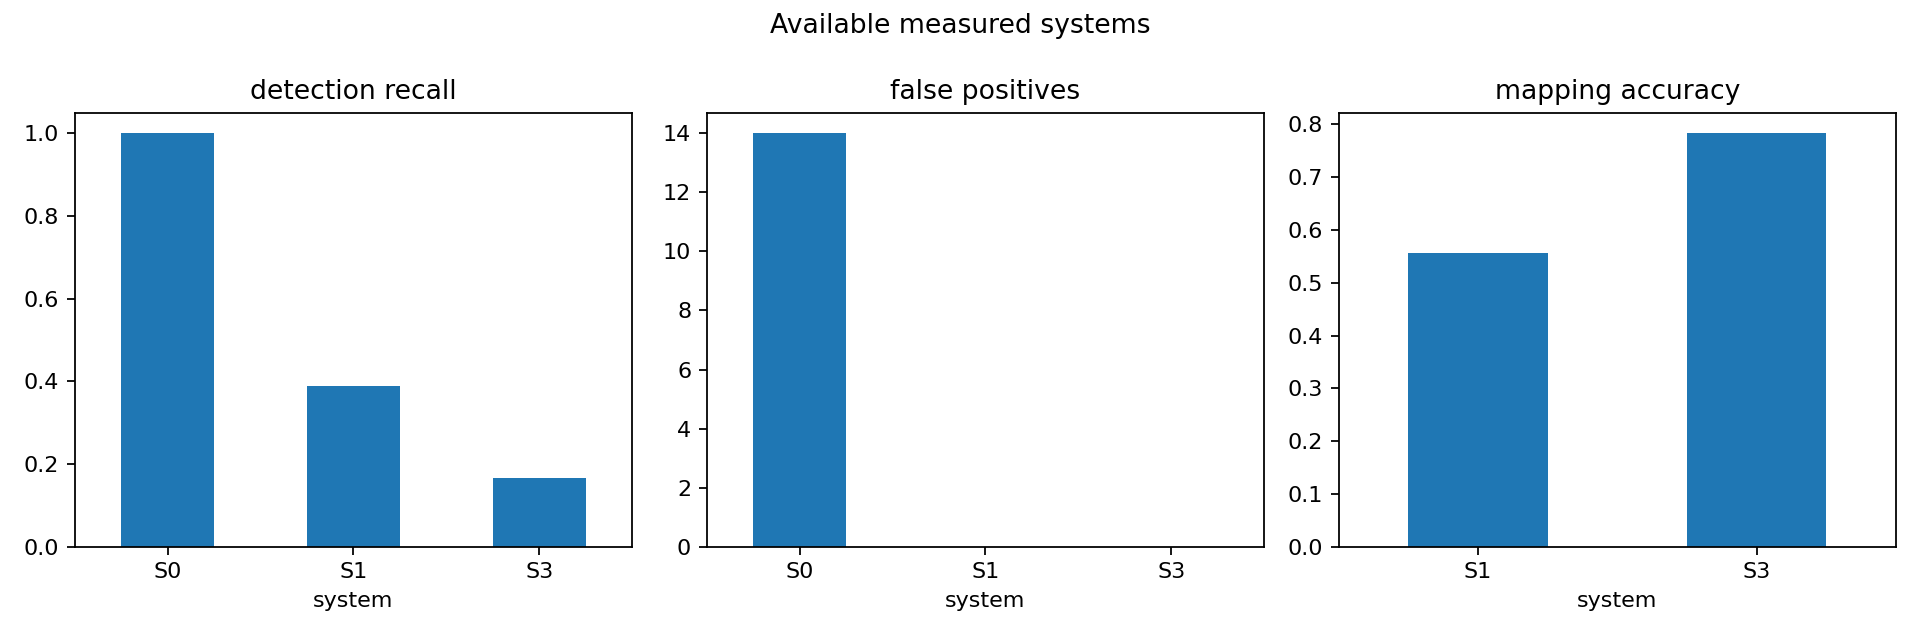

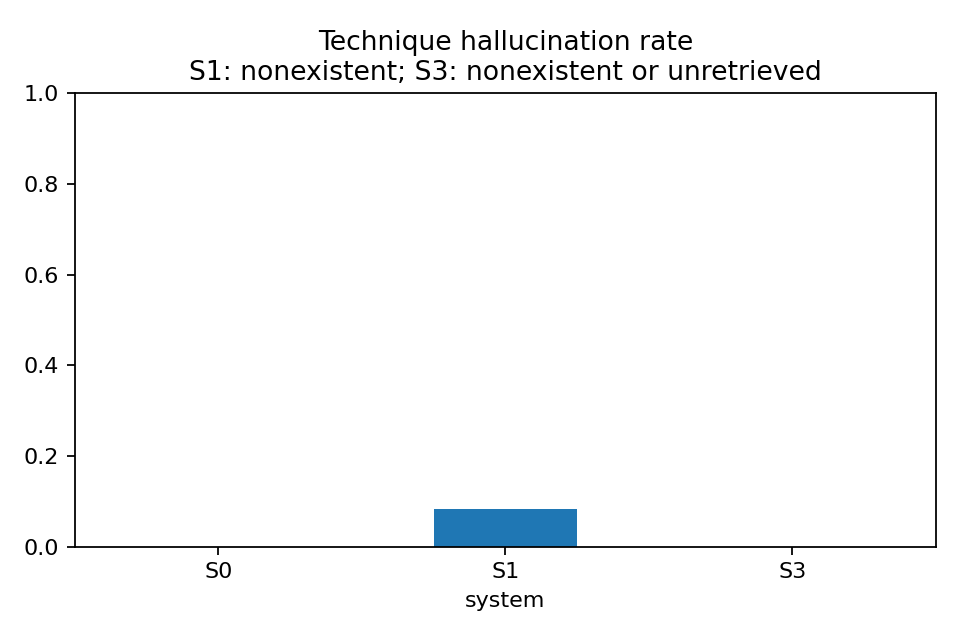

S1 has no retriever: its hallucination rate measures nonexistent IDs; S3 also measures retrieval violations. S0 mapping is not applicable.


In [12]:
from cyberagents.evaluate import evaluate_saved, render_results
for path in sorted(pathlib.Path('outputs').glob('S*_seed*.json')):
    measured = evaluate_saved(path, kb)
    print(json.dumps({k: v for k, v in measured.items() if k != 'errors'}, indent=2))
table = render_results()
display(table)
from IPython.display import Image, Markdown, display
for name in ['comparison.png', 'hallucinations.png']:
    display(Image(filename=str(pathlib.Path('outputs') / name)))
print('S1 has no retriever: its hallucination rate measures nonexistent IDs; S3 also measures retrieval violations. S0 mapping is not applicable.')


## 13. Error analysis

In [13]:
import pandas as pd
errors = pd.read_csv('outputs/error_analysis.csv')
display(errors)
print('Every missed scenario and false-positive incident is listed. Inspect the corresponding saved clusters, findings, candidates and validation logs to distinguish pre-filter, dismissal, retrieval, mapping and correlation errors.')


,system,seed,kind,item,matched_scenario,cause
0,S0,2026,false_positive,s0-i1,B4,Benign/background evidence retained as an inci...
1,S0,2026,false_positive,s0-i2,__background__,Benign/background evidence retained as an inci...
2,S0,2026,false_positive,s0-i10,B1,Benign/background evidence retained as an inci...
3,S0,2026,false_positive,s0-i11,__background__,Benign/background evidence retained as an inci...
4,S0,2026,false_positive,s0-i12,B3,Benign/background evidence retained as an inci...
...,...,...,...,...,...,...
63,S3,7,miss,A1,A1,Analyst dismissal/correlation
64,S3,7,miss,A2,A2,Analyst dismissal/correlation
65,S3,7,miss,A3,A3,Analyst dismissal/correlation
66,S3,7,miss,A4,A4,Analyst dismissal/correlation


Every missed scenario and false-positive incident is listed. Inspect the corresponding saved clusters, findings, candidates and validation logs to distinguish pre-filter, dismissal, retrieval, mapping and correlation errors.


## 14. Rendered A6 incident report

In [14]:
from cyberagents.evaluate import render_a6_demo
if s3 is not None:
    try:
        report = render_a6_demo('outputs/S3_seed42.json', 'outputs/demo_incident.md')
        display(Markdown(report))
    except ValueError as error:
        print(str(error))
else:
    print('No real S3 result yet; an A6 response report cannot be claimed.')


# Compromise of SSH Server via Brute Force, Privilege Escalation, and Data Exfiltration

Synthetic-data demonstration; recommendations only.

Severity: critical | Confidence: 0.95

Incident inc-001 details a critical compromise of the SSH server (ssh-src / 10.0.0.10) originating from external IP 203.0.113.75. The attack began with port reconnaissance (T1595.001), followed by brute-force authentication against the deploy user (T1110), unauthorized privilege escalation via sudo to obtain a root shell (T1548.003), and subsequent data exfiltration of approximately 150MB over a non-standard port 4444 to an external destination (T1041). Targeted containment, thorough investigation, and strict preventive controls are required.

## Timeline

- 2026-10-16T20:37:10Z: T1595.001 — External port scanning activity targeting the SSH server from source IP 203.0.113.75.
- 2026-10-16T20:47:10Z: T1110 — Brute-force password guessing leading to successful SSH authentication for the deploy user from 203.0.113.75.
- 2026-10-16T20:54:10Z: T1548.003 — Post-exploitation root shell escalation via sudo by the deploy user.
- 2026-10-16T21:07:10Z: T1041 — Outbound data transfer exfiltrating 150MB of data to external IP 198.51.100.200 on port 4444.

## Recommended actions

- P1: Block attacker IP address on perimeter firewall (target: 203.0.113.75)

```text
iptables -A INPUT -s 203.0.113.75 -j DROP
```

- P1: Isolate compromised host from internal network (target: ssh-srv (10.0.0.10))

```text
ip link set eth0 down
```

- P1: Terminate active sessions and disable compromised deploy user account temporarily (target: deploy)

```text
pkill -u deploy && usermod -L deploy
```


## ATT&CK mitigations

- M1056 Pre-compromise → T1595.001
- M1018 User Account Management → T1110
- M1036 Account Use Policies → T1110
- M1032 Multi-factor Authentication → T1110
- M1027 Password Policies → T1110
- M1022 Restrict File and Directory Permissions → T1548.003
- M1028 Operating System Configuration → T1548.003
- M1026 Privileged Account Management → T1548.003
- M1031 Network Intrusion Prevention → T1041
- M1057 Data Loss Prevention → T1041

Evaluation: this incident covers 5 of the A6 stages.


## 15. Conclusions and limitations

Use the measured table above to assess the targets from `docs/goal.md`. A missed target remains a missed target; do not tune after System freeze or replace held-out results.

The data is synthetic and does not establish real-world detection performance. LLM results can vary despite temperature zero; cached responses make repeated analysis reproducible. Rates and model availability depend on the provider account. S1 intentionally retains raw outputs for baseline measurement. All response commands are examples for human review; no action is executed.

A complete submission needs all systems across all catalog seeds, semantic retrieval checks, a real full-system run, error analysis, an A6 demonstration where detected, and a fresh-Colab Run All. Missing checks must remain labelled pending.
